<a href="https://colab.research.google.com/github/denverkim/DM_FALL2026/blob/main/DM26_LAB5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 로지스틱 회귀분석

In [4]:
# logit_train.csv 파일을 불러온 후 statsmodels를 이용해 로지스틱 회귀모델을 만들고, 합격 여부를 예측하시오.
import pandas as pd

train = pd.read_csv('/content/logit_train.csv')
train = train.drop('Unnamed: 0', axis=1)
train.head()

,gmat,gpa,work_experience,admitted
0,780,4.0,3,1
1,750,3.9,4,1
2,690,3.3,3,0
3,710,3.7,5,1
4,680,3.9,4,0


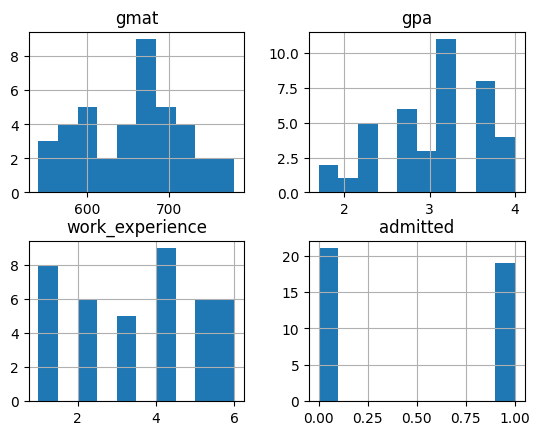

In [7]:
# EDA
import matplotlib.pyplot as plt

train.hist()
plt.show()

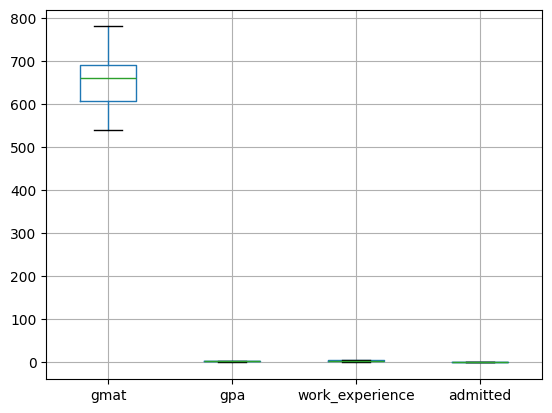

In [8]:
train.boxplot() # 스케일링 필요!
plt.show()

In [9]:
train.describe()

,gmat,gpa,work_experience,admitted
count,40.000000,40.000000,40.000000,40.000000
mean,654.000000,3.095000,3.425000,0.475000
std,61.427464,0.631218,1.737778,0.505736
min,540.000000,1.700000,1.000000,0.000000
25%,607.500000,2.700000,2.000000,0.000000
50%,660.000000,3.300000,4.000000,0.000000
75%,690.000000,3.700000,5.000000,1.000000
max,780.000000,4.000000,6.000000,1.000000


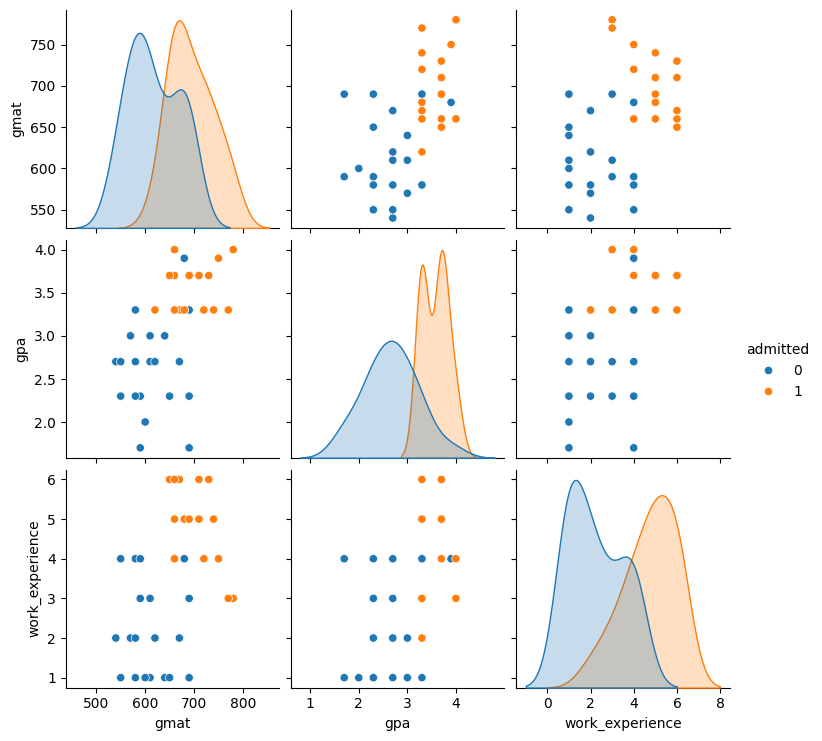

In [11]:
import seaborn as sns

sns.pairplot(train, hue='admitted')

In [12]:
# gmat, gpa, work_experience를 입력 변수 X로 설정
x_train = train[['gmat', 'gpa', 'work_experience']]
x_train.head()

,gmat,gpa,work_experience
0,780,4.0,3
1,750,3.9,4
2,690,3.3,3
3,710,3.7,5
4,680,3.9,4


In [15]:
# admitted를 정답 변수 Y로 설정
y_train=train['admitted']
y_train.head()

,admitted
0,1
1,1
2,0
3,1
4,0


In [17]:
# 로지스틱 회귀 모델 학습
import statsmodels.api as sm

logit = sm.Logit(y_train, sm.add_constant(x_train))
result = logit.fit()
result.summary()

Optimization terminated successfully.
         Current function value: 0.214131
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               admitted   No. Observations:                   40
Model:                          Logit   Df Residuals:                       36
Method:                           MLE   Df Model:                            3
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.6905
Time:                        11:29:37   Log-Likelihood:                -8.5652
converged:                       True   LL-Null:                       -27.676
Covariance Type:            nonrobust   LLR p-value:                 2.537e-08
===================================================================================
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -22.0233      9.086     -2.424      0.015     -39.831      -4.216
gmat                0.0157      0.015      1.078      0.281      -0.013       0.044
gpa                 2.4545      2.008      1.222      0.222      -1.481       6.390
work_experience     1.0027      0.573      1.749      0.080      -0.121       2.127
===================================================================================
"""

In [18]:
# logit_test.csv를 불러온 후 모델을 평가하시오.
test = pd.read_csv('/content/logit_test.csv')
test = test.drop('Unnamed: 0', axis=1)
test.head()

,gmat,gpa,work_experience,admitted
0,590,2.0,3,0
1,740,3.7,4,1
2,680,3.3,6,1
3,610,2.3,1,0
4,710,3.0,5,1


In [20]:
# x와 y 분리
x_test = test[['gmat', 'gpa', 'work_experience']]
y_test = test['admitted']

In [22]:
# 테스트 데이터의 합격 확률 예측
y_pred = result.predict(sm.add_constant(x_test))
y_pred

,0
0,0.007900
1,0.937027
2,0.941616
3,0.003056
4,0.819506


In [25]:
# 예측값을 0 또는 1로 변환
list(map(round, y_pred))

[0, 1, 1, 0, 1]

In [28]:
# 실제 합격 여부와 예측 결과 비교
y_test.values

array([0, 1, 1, 0, 1])

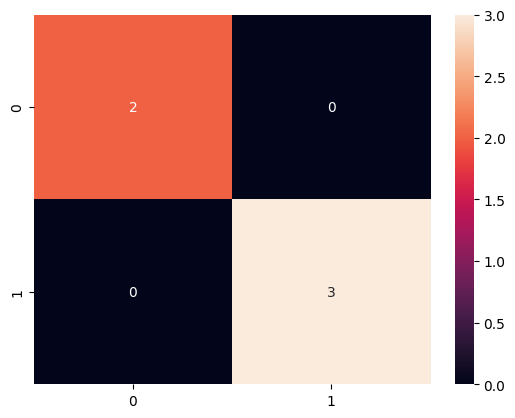

In [34]:
# 혼동행렬 계산
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(confusion_matrix(y_test, list(map(round, y_pred))), annot=True)
plt.show()

In [35]:
# 정확도 계산
from sklearn.metrics import accuracy_score
accuracy_score(y_test, list(map(round, y_pred)))

1.0

In [36]:
# 분류리포트
from sklearn.metrics import classification_report
print(classification_report(y_test, list(map(round, y_pred))))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



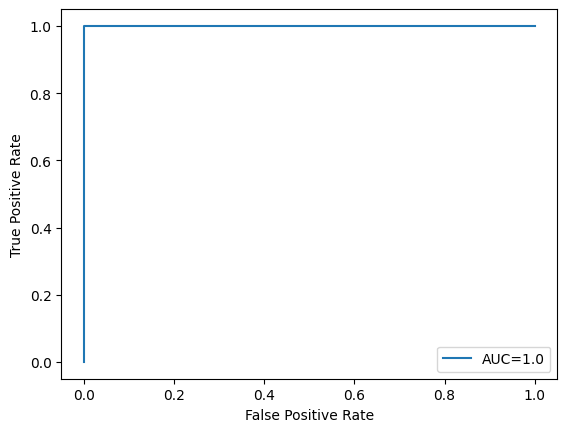

In [41]:
# ROC Curve
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, _ = roc_curve(y_test, result.predict(sm.add_constant(x_test)))
auc = roc_auc_score(y_test, result.predict(sm.add_constant(x_test)))

plt.plot(fpr,tpr,label="AUC="+str(auc))
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc=4)
plt.show()
